In [4]:
# ============================================================
# HÜCRE 1: Gerekli Kütüphanelerin Kurulumu
# Bu hücrede Gradio kütüphanesi kurulmaktadır. Gradio,
# eğitilen modelin web tabanlı bir arayüz üzerinden
# kullanılmasını sağlayacaktır.
# ============================================================
!pip install -q gradio

In [5]:
# ============================================================
# HÜCRE 2: Kütüphanelerin İçe Aktarılması
# Bu hücrede PyTorch, Torchvision, Scikit-Learn ve diğer
# yardımcı kütüphaneler projeye dahil edilmektedir.
# Ayrıca model değerlendirmesinde kullanılacak metrikler
# yüklenmektedir.
# ============================================================
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets
from torchvision import transforms
from torchvision import models

from torch.utils.data import DataLoader

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

import numpy as np
from tqdm import tqdm

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.is_available())

PyTorch: 2.14.1+cu130
GPU: True


In [6]:
# ============================================================
# HÜCRE 3: Görüntü Ön İşleme ve Veri Dönüşümleri
# Bu hücrede CIFAR-10 görüntüleri modele uygun hale
# getirilmektedir. Görüntüler yeniden boyutlandırılmakta,
# normalize edilmekte ve eğitim verileri için veri artırma
# (data augmentation) işlemleri uygulanmaktadır.
# ============================================================
transform_train = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.4914,0.4822,0.4465],
        std=[0.2023,0.1994,0.2010]
    )
])

transform_test = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.4914,0.4822,0.4465],
        std=[0.2023,0.1994,0.2010]
    )
])

In [7]:
# ============================================================
# HÜCRE 4: CIFAR-10 Veri Setinin Yüklenmesi
# Bu hücrede CIFAR-10 veri seti indirilmekte ve eğitim ile
# test kümeleri oluşturulmaktadır. DataLoader yapıları ile
# veriler mini-batch halinde modele aktarılacaktır.
# ============================================================
train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform_train
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform_test
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

classes = train_dataset.classes

print(classes)

100%|██████████| 170M/170M [12:35<00:00, 226kB/s]


['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [8]:
# ============================================================
# HÜCRE 5: ResNet18 Modelinin Oluşturulması
# Bu hücrede önceden eğitilmiş ResNet18 mimarisi
# kullanılmaktadır. Son katman CIFAR-10 veri setindeki
# 10 farklı sınıfı tahmin edecek şekilde yeniden
# yapılandırılmıştır.
# ============================================================
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

model = models.resnet18(weights="DEFAULT")

model.fc = nn.Linear(
    model.fc.in_features,
    10
)

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print(model)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 202MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [9]:
# ============================================================
# HÜCRE 6: Modelin Eğitilmesi
# Bu hücrede ResNet18 modeli eğitim verileri üzerinde
# eğitilmektedir. Kayıp fonksiyonu olarak CrossEntropyLoss,
# optimizasyon algoritması olarak ise Adam kullanılmaktadır.
# ============================================================
epochs = 10

for epoch in range(epochs):

    model.train()

    running_loss = 0

    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    print(
        f"Epoch {epoch+1}/{epochs} "
        f"Loss: {running_loss/len(train_loader):.4f}"
    )

100%|██████████| 782/782 [04:05<00:00,  3.19it/s]


Epoch 1/10 Loss: 0.5606


100%|██████████| 782/782 [04:13<00:00,  3.09it/s]


Epoch 2/10 Loss: 0.3454


100%|██████████| 782/782 [04:12<00:00,  3.09it/s]


Epoch 3/10 Loss: 0.2647


... (10 outputs left out)

100%|██████████| 782/782 [04:13<00:00,  3.09it/s]


Epoch 9/10 Loss: 0.0951


100%|██████████| 782/782 [04:12<00:00,  3.10it/s]

Epoch 10/10 Loss: 0.0835


In [10]:
# ============================================================
# HÜCRE 7: Model Performansının Değerlendirilmesi
# Bu hücrede test veri seti kullanılarak modelin başarımı
# ölçülmektedir. Accuracy, Precision, Recall ve F1-Score
# değerleri hesaplanarak performans analizi yapılmaktadır.
# ============================================================
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        _, preds = torch.max(outputs,1)

        all_preds.extend(
            preds.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

acc = accuracy_score(
    all_labels,
    all_preds
)

precision = precision_score(
    all_labels,
    all_preds,
    average='weighted'
)

recall = recall_score(
    all_labels,
    all_preds,
    average='weighted'
)

f1 = f1_score(
    all_labels,
    all_preds,
    average='weighted'
)

print("Accuracy :", acc)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.9149
Precision: 0.917180258246178
Recall   : 0.9149
F1 Score : 0.9155371064172619


In [11]:
# ============================================================
# HÜCRE 8: Eğitilmiş Modelin Kaydedilmesi
# Bu hücrede eğitim tamamlandıktan sonra model ağırlıkları
# kaydedilmektedir. Böylece model daha sonra yeniden eğitim
# gerektirmeden kullanılabilecektir.
# ============================================================
torch.save(
    model.state_dict(),
    "resnet18_cifar10.pth"
)

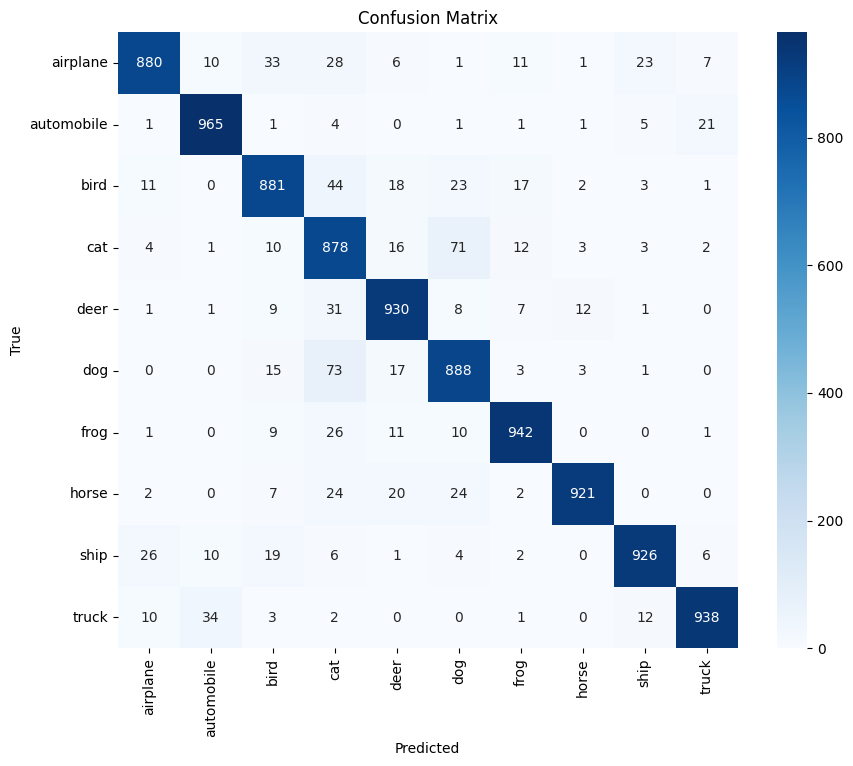

              precision    recall  f1-score   support

    airplane       0.94      0.88      0.91      1000
  automobile       0.95      0.96      0.95      1000
        bird       0.89      0.88      0.89      1000
         cat       0.79      0.88      0.83      1000
        deer       0.91      0.93      0.92      1000
         dog       0.86      0.89      0.87      1000
        frog       0.94      0.94      0.94      1000
       horse       0.98      0.92      0.95      1000
        ship       0.95      0.93      0.94      1000
       truck       0.96      0.94      0.95      1000

    accuracy                           0.91     10000
   macro avg       0.92      0.91      0.92     10000
weighted avg       0.92      0.91      0.92     10000



In [12]:
# ============================================================
# HÜCRE 9: Confusion Matrix ve Classification Report
# Bu hücrede modelin sınıf bazındaki performansı
# incelenmektedir. Karışıklık matrisi ve sınıflandırma
# raporu oluşturularak hangi sınıfların daha başarılı
# tahmin edildiği analiz edilmektedir.
# ============================================================
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10,8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")

plt.show()

print(
    classification_report(
        all_labels,
        all_preds,
        target_names=classes
    )
)


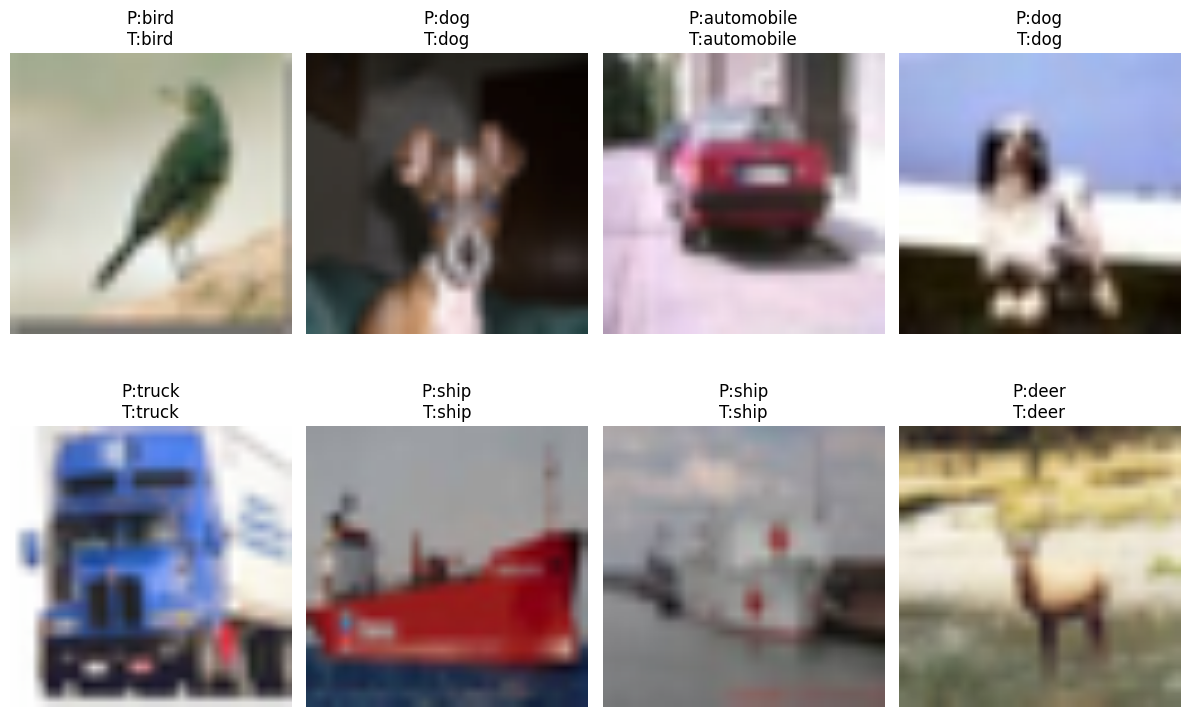

In [15]:
# ============================================================
# HÜCRE 10: Rastgele Tahmin Örneklerinin Gösterilmesi
# Bu hücrede test veri setinden seçilen örnek görüntüler
# üzerinde model tahminleri görselleştirilmektedir.
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

model.eval()

fig = plt.figure(figsize=(12,8))

for i in range(8):

    image, label = test_dataset[np.random.randint(len(test_dataset))]

    image_input = image.unsqueeze(0).to(device)

    with torch.no_grad():

        output = model(image_input)

        prediction = torch.argmax(output,1).item()

    image_show = image.permute(1,2,0).cpu().numpy()

    image_show = (
        image_show *
        np.array([0.2023,0.1994,0.2010])
        +
        np.array([0.4914,0.4822,0.4465])
    )

    image_show = np.clip(
        image_show,
        0,
        1
    )

    plt.subplot(2,4,i+1)

    plt.imshow(image_show)

    plt.title(
        f"P:{classes[prediction]}\nT:{classes[label]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()


In [16]:
# ============================================================
# HÜCRE 11: Gradio Web Arayüzü
# Bu hücrede eğitilen model web tabanlı bir uygulama olarak
# sunulmaktadır. Kullanıcı yüklediği görüntü için sınıf
# tahmini alabilmektedir.
# ============================================================
import gradio as gr
from PIL import Image

classes = [
    'airplane',
    'automobile',
    'bird',
    'cat',
    'deer',
    'dog',
    'frog',
    'horse',
    'ship',
    'truck'
]

def predict(image):

    image = transform_test(image)
    image = image.unsqueeze(0).to(device)

    model.eval()

    with torch.no_grad():

        outputs = model(image)

        probs = torch.softmax(outputs, dim=1)

        probs = probs.cpu().numpy()[0]

    return {
        classes[i]: float(probs[i])
        for i in range(len(classes))
    }

demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil"),
    outputs=gr.Label(num_top_classes=3),
    title="CIFAR-10 Image Classifier",
    description="ResNet18 model trained on CIFAR-10"
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://84fac23c688f4ca50d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
